# Hypothesis Testing: Education and Salary

## Research Question

Do occupations requiring a Bachelor's Degree have higher median annual salaries than occupations requiring a High School Diploma or Equivalent?

## Test Statistic

I will compare the **difference in mean median annual salary** between the two education groups.

$$
\text{Test Statistic} = \bar{x}_{\text{Bachelor's}} - \bar{x}_{\text{High School}}
$$

## Null Hypothesis

There is no difference in mean median annual salary between occupations requiring a Bachelor's Degree and occupations requiring a High School Diploma or Equivalent.

$$
H_0:
\mu_{\text{Bachelor's}} - \mu_{\text{High School}} = 0
$$

## Alternative Hypothesis

Occupations requiring a Bachelor's Degree have a higher mean median annual salary than occupations requiring a High School Diploma or Equivalent.

$$
H_A:
\mu_{\text{Bachelor's}} - \mu_{\text{High School}} > 0
$$

In [1]:
# 1. Importing libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 2. Loading the dataset

df = pd.read_csv(
    "career_explorer_occupational_level_data_1192_rows.csv"
)

df.head()

,geography,soc,occupational_title,job_title_soc,occupational_category,job_profile,url,estimated_employment,estimated_employment_year,projected_employment,...,ind_1,ind_2,ind_3,ind_4,ind_5,ind_6,ind_7,ind_8,ind_9,ind_10
0,State of Iowa,11-1011,Chief Executive,Chief Executive (11-1011),Management,Top executive responsible for overall strategi...,https://www.careeronestop.org/Videos/careerone...,4215,2022,3920,...,"Agriculture, Forestry, Fishing and Hunting",Construction,"Self Employed and Unpaid Family Workers, All Jobs",Manufacturing,Finance and Insurance,Other Services (except Government),Retail Trade,Transportation and Warehousing,Health Care and Social Assistance,Real Estate and Rental and Leasing
1,State of Iowa,11-9121,Natural Sciences Manager,Natural Sciences Manager (11-9121),Management,Coordinates research and development activitie...,https://www.careeronestop.org/Videos/careerone...,620,2022,675,...,Government,"Professional, Scientific, and Technical Services",Educational Services,Manufacturing,Other Services (except Government),Wholesale Trade,NaN,NaN,NaN,NaN
2,State of Iowa,15-1243,Database Architect,Database Architect (15-1243),Computer & Mathematical,Design and build databases to meet the storage...,https://www.careeronestop.org/Videos/careerone...,275,2022,300,...,Finance and Insurance,Management of Companies and Enterprises,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,State of Iowa,17-2072,"Electronics Engineer, Except Computer","Electronics Engineer, Except Computer (17-2072)",Architecture & Engineering,Designs and develops electronic components and...,https://www.careeronestop.org/Videos/careerone...,380,2022,435,...,Information,Manufacturing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,State of Iowa,19-1011,Animal Scientist,Animal Scientist (19-1011),"Life, Physical, & Social Science","Conducts research on genetics, nutrition, repr...",https://www.careeronestop.org/Videos/careerone...,305,2022,315,...,"Agriculture, Forestry, Fishing and Hunting",Wholesale Trade,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# 3. Creating the two education groups

test_df = df[
    df["typical_education_requirement"].isin([
        "High School Diploma or Equivalent",
        "Bachelor's Degree"
    ])
][
    ["typical_education_requirement", "median_annual_salary"]
].dropna()

test_df.head()

,typical_education_requirement,median_annual_salary
0,Bachelor's Degree,178534.0
1,Bachelor's Degree,102883.0
2,Bachelor's Degree,131375.0
3,Bachelor's Degree,90908.0
4,Bachelor's Degree,95675.0


In [4]:
# 4. Checking sample sizes

group_counts = test_df["typical_education_requirement"].value_counts()

print("-" * 61)
print(f"{'Education Requirement':<45} | {'Sample Size':>12}")
print("-" * 61)

for education, count in group_counts.items():
    print(f"{education:<45} | {count:>12}")

print("-" * 61)

-------------------------------------------------------------
Education Requirement                         |  Sample Size
-------------------------------------------------------------
High School Diploma or Equivalent             |        15992
Bachelor's Degree                             |         8698
-------------------------------------------------------------


## 2. Observed Test Statistic

The test statistic is the difference in mean median annual salary between occupations requiring a Bachelor's Degree and occupations requiring a High School Diploma or Equivalent.

$$
\text{Observed Difference} = \bar{x}_{\text{Bachelor's}} - \bar{x}_{\text{High School}}
$$

In [5]:
# 5. Calculating the observed test statistic

bachelors_mean = test_df.loc[
    test_df["typical_education_requirement"] == "Bachelor's Degree",
    "median_annual_salary"
].mean()

high_school_mean = test_df.loc[
    test_df["typical_education_requirement"] == "High School Diploma or Equivalent",
    "median_annual_salary"
].mean()

observed_difference = bachelors_mean - high_school_mean

print("-" * 65)
print(f"{'Group':<42} | {'Mean Salary ($)':>18}")
print("-" * 65)
print(f"{'Bachelor Degree':<42} | {bachelors_mean:>18,.2f}")
print(f"{'High School Diploma or Equivalent':<42} | {high_school_mean:>18,.2f}")
print("-" * 65)
print(f"{'Observed Difference':<42} | {observed_difference:>18,.2f}")
print("-" * 65)

-----------------------------------------------------------------
Group                                      |    Mean Salary ($)
-----------------------------------------------------------------
Bachelor Degree                            |          72,307.39
High School Diploma or Equivalent          |          46,600.90
-----------------------------------------------------------------
Observed Difference                        |          25,706.49
-----------------------------------------------------------------


#### **Finding:**

*Occupations requiring a Bachelor's Degree have a higher mean median annual salary than occupations requiring a High School Diploma or Equivalent.*

The observed difference is:

$$ 72{,}307.39 - 46{,}600.90 = 25{,}706.49 $$

*This means the Bachelor's Degree group has an average median annual salary that is approximately **`$25,706` higher** than the High School Diploma or Equivalent group.*

*However, this observed difference alone does not tell us whether the difference could reasonably occur by chance. A permutation test will be used next to evaluate that possibility.*

## 3. Permutation Test

Under the null hypothesis, education requirement should not be associated with salary. If the null hypothesis is true, the education labels can be randomly shuffled while keeping the salary values unchanged.

For each permutation, I will calculate:

$$
\text{Permuted Difference} = \bar{x}_{\text{Bachelor's}} - \bar{x}_{\text{High School}}
$$

I will repeat this process many times to create a null distribution of salary differences.

In [6]:
# 6. Running the permutation test

np.random.seed(42)

n_permutations = 10000
permuted_differences = []

for i in range(n_permutations):
    
    shuffled_labels = np.random.permutation(
        test_df["typical_education_requirement"].values
    )
    
    shuffled_df = test_df.copy()
    shuffled_df["shuffled_education"] = shuffled_labels
    
    bachelors_perm_mean = shuffled_df.loc[
        shuffled_df["shuffled_education"] == "Bachelor's Degree",
        "median_annual_salary"
    ].mean()
    
    high_school_perm_mean = shuffled_df.loc[
        shuffled_df["shuffled_education"] == "High School Diploma or Equivalent",
        "median_annual_salary"
    ].mean()
    
    permuted_difference = bachelors_perm_mean - high_school_perm_mean
    
    permuted_differences.append(permuted_difference)

len(permuted_differences)

10000

### P-value

Because my alternative hypothesis predicts that the Bachelor's Degree group has a higher mean salary, this is a **one-sided permutation test**.

The p-value is the proportion of permuted differences that are greater than or equal to the observed difference.

$$
p\text{-value} = \frac{\text{Number of permuted differences } \geq \text{ observed difference}} {\text{Total number of permutations}}
$$

In [7]:
# 7. Calculating the one-sided p-value

permuted_differences = np.array(permuted_differences)

p_value = np.mean(
    permuted_differences >= observed_difference
)

print("-" * 55)
print(f"{'Observed Difference ($)':<35} | {observed_difference:>15,.2f}")
print(f"{'Number of Permutations':<35} | {n_permutations:>15}")
print(f"{'P-value':<35} | {p_value:>15.4f}")
print("-" * 55)

-------------------------------------------------------
Observed Difference ($)             |       25,706.49
Number of Permutations              |           10000
P-value                             |          0.0000
-------------------------------------------------------


#### **Finding:**

*The observed salary difference between the Bachelor's Degree group and the High School Diploma or Equivalent group is **`$25,706.49`**.*

None of the 10,000 permutation differences were as large as the observed difference, so the estimated p-value is less than:

$$
\frac{1}{10{,}000} = 0.0001
$$

*Because this p-value is extremely small, the observed difference would be very unlikely under the null hypothesis. This provides strong evidence against the null hypothesis and supports the alternative hypothesis that occupations requiring a Bachelor's Degree have a higher mean median annual salary than occupations requiring a High School Diploma or Equivalent.*

### Permutation Distribution

The permutation distribution shows the salary differences expected if education requirement were not associated with salary. I compared this null distribution with the observed salary difference.

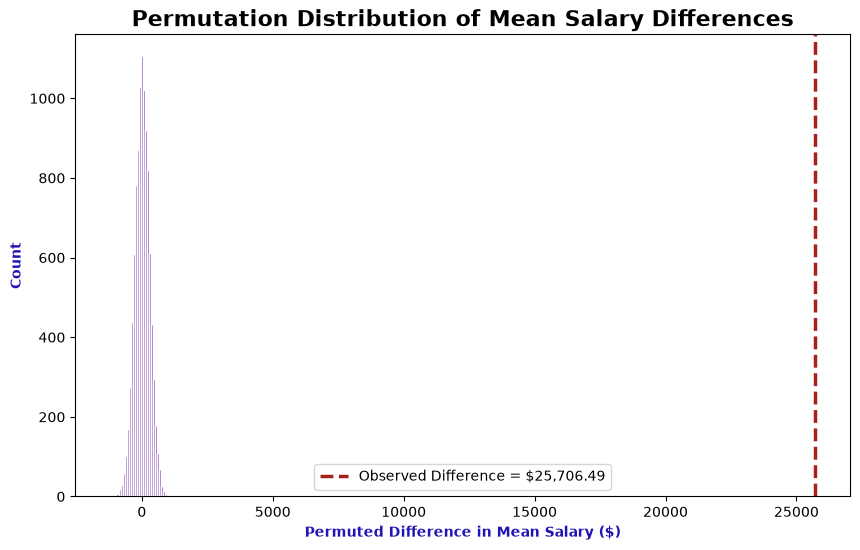

In [8]:
# 8. Plotting the permutation distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    permuted_differences,
    bins=30,
    color="#5B069B",
    edgecolor="white"
)

plt.axvline(
    observed_difference,
    color="#A6201C",
    linestyle="--",
    linewidth=2.5,
    label=f"Observed Difference = ${observed_difference:,.2f}"
)

plt.title(
    "Permutation Distribution of Mean Salary Differences",
    fontweight="bold",
    fontsize=16
)

plt.xlabel(
    "Permuted Difference in Mean Salary ($)",
    fontweight="bold",
    color="#2114B5"
)

plt.ylabel(
    "Count",
    fontweight="bold",
    color="#2114B5"
)

plt.legend()

plt.show()

#### **Finding:**

*The permutation distribution is centered close to zero, which is what we would expect under the null hypothesis if education requirement were not associated with salary.*

*The observed difference of **`$25,706.49`** lies far to the right of the permutation distribution and is much larger than any of the differences produced by the 10,000 random permutations.*

*This visual result is consistent with the very small p-value and provides strong evidence against the null hypothesis.*

## 4. Hypothesis Test Conclusion

The permutation test produced an observed mean salary difference of **`$25,706.49`** between occupations requiring a Bachelor's Degree and occupations requiring a High School Diploma or Equivalent.

None of the 10,000 permuted differences were as large as the observed difference, giving an estimated p-value of less than:

$$ 0.0001 $$

Because the p-value is much smaller than a typical significance level of:

$$ \alpha = 0.05 $$

I **reject the null hypothesis**.

There is strong statistical evidence that occupations requiring a Bachelor's Degree have a higher mean median annual salary than occupations requiring a High School Diploma or Equivalent.